# Week 7 — Exercise 1: Database search

**27200 Data-driven Bioengineering**

A tandem mass spectrum (MS/MS) is a list of fragment masses. Reading the peptide sequence from it
directly is hard, so most proteomics does the opposite: **predict** the spectrum of every peptide that
*could* be in the sample, and find the prediction that best matches each measured spectrum. That is a
database search. You will build one, from the genome to a list of identified peptides with a
controlled error rate:

| Step | What | Tool |
|---|---|---|
| 1 | Translate the human protein-coding genes into a protein database | Biopython |
| 2 | Digest every protein with trypsin, in silico | pyOpenMS |
| 3 | Add decoys: reversed proteins that cannot be in the sample | |
| 4 | Score each spectrum against the peptides of matching mass | hyperscore |
| 5 | Estimate the false discovery rate and keep the confident matches | target–decoy |
| 6 | Look at what you found | |

The spectra are 2,000 MS/MS spectra from one LC-MS/MS run of a HeLa cell digest
([PXD045495](https://www.ebi.ac.uk/pride/archive/projects/PXD045495), Orbitrap Eclipse). Nothing here
needs a GPU. The whole notebook runs in about two minutes; the slower cells show a progress bar.

## Setup

In [ ]:
# pyOpenMS: mass spectrometry toolbox (we use its trypsin rules)
# Biopython: reading FASTA files and translating DNA
# pyteomics: reading spectra in MGF format;  spectrum_utils: drawing annotated spectra
!pip install -q pyopenms biopython pyteomics spectrum_utils

In [ ]:
import os, re, gzip, math, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm            # progress bars for the slow loops
from Bio import SeqIO
import pyopenms as oms
from pyteomics import mgf

# Download the spectra and the reference results from the course repository (only once)
BASE = "https://raw.githubusercontent.com/UadKLab/27200_Data-Driven-Bioengineering/main/weeks/week07_proteomics/data/"
for f in ["hela_2000.mgf", "hela_2000_reference.csv"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + f, f)

PROTON, H2O = 1.007276, 18.010565      # masses of a proton and of a water molecule (Da)

# Monoisotopic residue masses: the mass each amino acid adds to a peptide chain.
# C is carbamidomethylated: during sample preparation every cysteine was reduced and alkylated with
# iodoacetamide, which adds 57.02 Da. We treat that as fixed, so it is already part of C's mass.
AA = {"G": 57.02146, "A": 71.03711, "S": 87.03203, "P": 97.05276, "V": 99.06841,
      "T": 101.04768, "C": 160.03065, "L": 113.08406, "I": 113.08406, "N": 114.04293,
      "D": 115.02694, "Q": 128.05858, "K": 128.09496, "E": 129.04259, "M": 131.04049,
      "H": 137.05891, "F": 147.06841, "R": 156.10111, "Y": 163.06333, "W": 186.07931}
print("ready")

ready


---
## 1 · From genome to protein database

A search engine can only find peptides that are in its database. Here we build that database
ourselves, from the coding sequences (CDS) of the **human genome annotation**: the stretches of DNA that
are translated into protein. [Ensembl](https://www.ensembl.org) publishes them as one FASTA file
(23 MB). We pin release 113 so everyone gets the same file.

In [ ]:
url = "https://ftp.ensembl.org/pub/release-113/fasta/homo_sapiens/cds/Homo_sapiens.GRCh38.cds.all.fa.gz"
if not os.path.exists("cds.fa.gz"):              # download once; afterwards reuse the local copy
    urllib.request.urlretrieve(url, "cds.fa.gz")

# Look at one record: beta-actin (gene ACTB). SeqIO reads the FASTA file one record at a time;
# each record has an id, a description line, and the DNA sequence.
with gzip.open("cds.fa.gz", "rt") as fh:
    for rec in SeqIO.parse(fh, "fasta"):
        if "gene_symbol:ACTB " in rec.description and "transcript_biotype:protein_coding" in rec.description:
            break                                # stop at the first ACTB coding sequence

print(rec.description[:150], "...\n")
print("DNA:    ", str(rec.seq[:60]), "...", len(rec.seq), "nucleotides")
# translate() reads the DNA three bases (one codon) at a time and writes the amino acid it codes for
print("protein:", str(rec.seq.translate()[:20]), "...", len(rec.seq) // 3, "codons")

ENST00000674681.1 cds chromosome:GRCh38:7:5526409:5530601:-1 gene:ENSG00000075624.17 gene_biotype:protein_coding transcript_biotype:protein_coding gen ...

DNA:     ATGGATGATGATATCGCCGCGCTCGTCGTCGACAACGGCTCCGGCATGTGCAAGGCCGGC ... 1128 nucleotides
protein: MDDDIAALVVDNGSGMCKAG ... 376 codons


Every protein-coding gene has one or more transcripts (splice variants), so there are many more CDS
records than genes. To keep the database simple we translate them all and keep **the longest protein
per gene**.

In [ ]:
proteins = {}                     # gene name -> (transcript id, protein sequence)
n_cds = n_skipped = 0

with gzip.open("cds.fa.gz", "rt") as fh:
    for rec in tqdm(SeqIO.parse(fh, "fasta"), desc="translating", unit=" CDS"):
        if "transcript_biotype:protein_coding" not in rec.description:
            continue                                   # skip pseudogenes, immune gene segments, etc.
        n_cds += 1
        if len(rec.seq) % 3 or "N" in rec.seq:         # not a whole number of codons, or unknown bases
            n_skipped += 1; continue
        prot = str(rec.seq.translate()).rstrip("*")    # translate; "*" is the stop codon, drop it
        if "*" in prot or len(prot) < 30:              # a stop codon in the middle = broken annotation
            n_skipped += 1; continue
        gene = re.search(r"gene_symbol:(\S+)", rec.description)   # pull the gene name out of the header
        gene = gene.group(1) if gene else rec.id
        if gene not in proteins or len(prot) > len(proteins[gene][1]):
            proteins[gene] = (rec.id, prot)            # keep this one if it is the longest so far

print(f"{n_cds} protein-coding CDS, {n_skipped} skipped -> {len(proteins)} genes, one protein each")
lengths = np.array([len(p) for _, p in proteins.values()])
print(f"protein length: median {np.median(lengths):.0f}, longest {lengths.max()} ({max(proteins, key=lambda g: len(proteins[g][1]))})")

100162 protein-coding CDS, 19144 skipped -> 20145 genes, one protein each
protein length: median 428, longest 35991 (TTN)


**Question 1.1** Keeping only the longest protein per gene throws information away. Which kinds of
peptides can this database never identify? Think of splicing, genetic variants and modifications.

**A:**

***-Alternative splicing isoforms:** Peptides containing exons unique to shorter splice variants.*

***-Mutations & Novel Variants:** Peptides with sequence changes (like cancer mutations in HeLa) that differ from the canonical reference sequence.*

***-Non-Canonical Proteins:** Peptides originating from alternative translation start sites, short ORFs, or untranslated regions (UTRs).*

***Question 1.2** HeLa cells carry the genome of human papillomavirus 18, and express its proteins.*


Would we find HPV peptides with this database?

**A:** *NO BECAUSE THE HPV IS NOT IN THE DATABASE, SO THE ANALYSIS IS BLIND TO THAT.*

---
## 2 · Digest in silico

Trypsin cuts **after lysine (K) and arginine (R)**, but **not when the next residue is proline (P)**.
Before letting pyOpenMS do it for 20,000 proteins, do it by hand for one: beta-actin. Below is its full
sequence, with a `|` at every place trypsin cuts.

In [ ]:
actb = proteins["ACTB"][1]

# A cut site is the position right after a K or R, unless the next residue is P.
cuts = [i + 1 for i in range(len(actb) - 1) if actb[i] in "KR" and actb[i + 1] != "P"]

# Cut the sequence into pieces at the sites, and print them joined by "|",
# starting a new line (at a cut) once a line holds about 60 residues
edges = [0] + cuts + [len(actb)]
pieces = [actb[edges[k]:edges[k + 1]] for k in range(len(edges) - 1)]
print(f"beta-actin, {len(actb)} residues, {len(cuts)} trypsin sites:\n")
line = []
for piece in pieces:
    if line and len("".join(line + [piece])) > 60:
        print("|".join(line) + "|"); line = []
    line.append(piece)
print("|".join(line))

beta-actin, 375 residues, 36 trypsin sites:

MDDDIAALVVDNGSGMCK|AGFAGDDAPR|AVFPSIVGRPR|HQGVMVGMGQK|
DSYVGDEAQSK|R|GILTLK|YPIEHGIVTNWDDMEK|IWHHTFYNELR|
VAPEEHPVLLTEAPLNPK|ANR|EK|MTQIMFETFNTPAMYVAIQAVLSLYASGR|
TTGIVMDSGDGVTHTVPIYEGYALPHAILR|LDLAGR|DLTDYLMK|ILTER|GYSFTTTAER|
EIVR|DIK|EK|LCYVALDFEQEMATAASSSSLEK|SYELPDGQVITIGNER|FR|
CPEALFQPSFLGMESCGIHETTFNSIMK|CDVDIR|K|DLYANTVLSGGTTMYPGIADR|MQK|
EITALAPSTMK|IK|IIAPPER|K|YSVWIGGSILASLSTFQQMWISK|QEYDESGPSIVHR|K|CF


Cutting at every `|` gives the **fully digested** peptides. In reality trypsin sometimes skips a site,
leaving two neighbouring peptides joined: a **missed cleavage**. And not every peptide is useful: very
short ones are found in many proteins, so they say little about which protein they came from, and
very long ones ionize and fragment poorly. So we keep peptides of **7 to 30 residues**, allowing
**one missed cleavage**.

The table lists the peptides from the start of the protein, in order, and whether each is kept.

***The database has to match reality:** If your in silico (computer-generated) database only assumes 100% perfect digestion, but the actual physical sample has a bunch of peptides where trypsin missed a cut, the search engine will look at the mass spec data and say, "I have no idea what this is," because that sequence isn't in its lookup table. Allowing missed cleavages means the database anticipates these real-world "mistakes."*

In [ ]:
# Split the protein at the cut sites into fully digested pieces
edges = [0] + cuts + [len(actb)]
pieces = [(edges[k], edges[k + 1]) for k in range(len(edges) - 1)]   # (start, end) of each piece

rows = []
for k, (s, e) in enumerate(pieces):
    for missed in (0, 1):                     # the piece alone, or joined to the next one
        if k + missed >= len(pieces):
            continue
        end = pieces[k + missed][1]
        pep = actb[s:end]
        keep = 7 <= len(pep) <= 30
        reason = "kept" if keep else ("too short" if len(pep) < 7 else "too long")
        rows.append(dict(start=s + 1, end=end, length=len(pep), missed_cleavages=missed,
                         peptide=pep, kept=reason))

table = pd.DataFrame(rows)
print("The first peptides of beta-actin, from the N-terminus:")
table.head(14)

The first peptides of beta-actin, from the N-terminus:


,start,end,length,missed_cleavages,peptide,kept
0,1,18,18,0,MDDDIAALVVDNGSGMCK,kept
1,1,28,28,1,MDDDIAALVVDNGSGMCKAGFAGDDAPR,kept
2,19,28,10,0,AGFAGDDAPR,kept
3,19,39,21,1,AGFAGDDAPRAVFPSIVGRPR,kept
4,29,39,11,0,AVFPSIVGRPR,kept
5,29,50,22,1,AVFPSIVGRPRHQGVMVGMGQK,kept
6,40,50,11,0,HQGVMVGMGQK,kept
7,40,61,22,1,HQGVMVGMGQKDSYVGDEAQSK,kept
8,51,61,11,0,DSYVGDEAQSK,kept
9,51,62,12,1,DSYVGDEAQSKR,kept


pyOpenMS knows the same rules (and the names of many other enzymes). It returns only the kept peptides;
check that they match the table.

In [ ]:
dig = oms.ProteaseDigestion()
dig.setEnzyme("Trypsin")              # cleave after K/R, not before P
dig.setMissedCleavages(1)             # also return peptides with one skipped site

def digest(seq, min_len=7, max_len=30):
    '''Tryptic peptides of one protein (length 7-30, up to one missed cleavage), as plain strings.'''
    out = []
    dig.digest(oms.AASequence.fromString(seq), out, min_len, max_len)
    return [p.toUnmodifiedString() for p in out]

by_pyopenms = set(digest(actb))
by_hand = set(table.peptide[table.kept == "kept"])
print(f"pyOpenMS: {len(by_pyopenms)} peptides | our table: {len(by_hand)} | identical: {by_pyopenms == by_hand}")

pyOpenMS: 47 peptides | our table: 47 | identical: True


---
## 3 · Decoys

A search always returns a best match, even for a spectrum of pure noise. To know how many of our
matches are wrong, we add **decoys**: peptides that we know cannot be in the sample. The usual trick
is to **reverse every protein** before digesting it. Reversed proteins have the same amino acid
composition and the same length and mass distributions as real ones, but they are not real
sequences. A wrong match is then equally likely to land on a decoy as on a real (target) peptide,
so **counting decoy matches tells us how many target matches are wrong**.

The next cell digests all 20,000 proteins and their reversed copies (about 30 seconds).

1,249,397 target and 1,247,962 decoy peptides


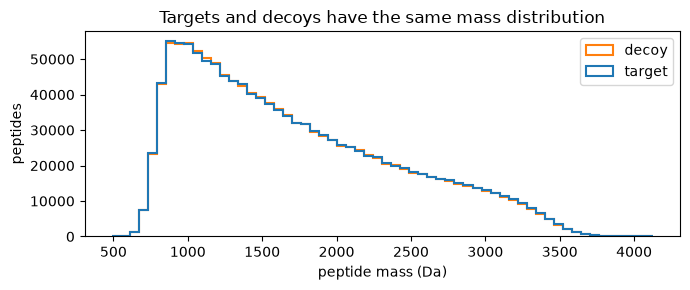

In [ ]:
rows, seen = [], {}                   # rows: one per unique peptide; seen: peptide -> its row number
for gene, (tid, prot) in tqdm(proteins.items(), desc="digesting", unit=" proteins"):
    for is_decoy, seq in ((False, prot), (True, prot[::-1])):     # the protein, and its reverse
        for pep in digest(seq):
            if any(c not in AA for c in pep):                     # skip rare letters (U, X)
                continue
            key = (pep, is_decoy)
            if key in seen:                                       # already seen in another gene:
                rows[seen[key]][3] += ";" + gene                  # just add this gene to its list
                continue
            seen[key] = len(rows)
            mass = sum(AA[c] for c in pep) + H2O                  # neutral peptide mass = residues + water
            rows.append([pep, mass, is_decoy, gene])

db = pd.DataFrame(rows, columns=["peptide", "mass", "decoy", "proteins"])
# A reversed sequence can, by chance, be a real peptide. Then it is not a decoy: drop it.
real = set(db.peptide[~db.decoy])
db = db[~(db.decoy & db.peptide.isin(real))]
# Sort by mass, so that the peptides of a given mass can be found quickly (step 4)
db = db.sort_values("mass").reset_index(drop=True)
masses = db.mass.to_numpy()
print(f"{(~db.decoy).sum():,} target and {db.decoy.sum():,} decoy peptides")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist([db.mass[~db.decoy], db.mass[db.decoy]], bins=60, label=["target", "decoy"], histtype="step", lw=1.5)
ax.set(xlabel="peptide mass (Da)", ylabel="peptides", title="Targets and decoys have the same mass distribution")
ax.legend(); plt.tight_layout(); plt.show()

---
## 4 · Scoring spectra

For each spectrum:

1. **Candidates**: from the precursor m/z and charge, compute the peptide mass, and take every
   peptide (target or decoy) within **10 ppm** of it. Mass accuracy is what makes the search fast:
   out of 2.5 million peptides, only about a hundred fit.
2. **Theoretical spectrum**: compute the b and y ions of each candidate.
3. **Score**: count and sum the observed peaks that match a theoretical ion within 0.02 Da, and
   combine them in the **hyperscore** (from the X!Tandem search engine):

$$\text{hyperscore} = \ln\!\Big(\sum I_\text{matched}\Big) + \ln(n_b!) + \ln(n_y!)$$

The factorials reward long runs of matched b *and* y ions, which a random peptide rarely has.

In [ ]:
# Each spectrum is a dict: "params" (title, precursor m/z, charge...), "m/z array", "intensity array"
spectra = list(mgf.read("hela_2000.mgf"))
print(len(spectra), "spectra; the first one:", spectra[0]["params"]["title"])

def by_ions(seq):
    '''The singly charged b and y ions of a peptide.'''
    m = np.array([AA[c] for c in seq])
    b = np.cumsum(m[:-1]) + PROTON                    # b1 ... b(n-1): first residues + a proton
    y = np.cumsum(m[::-1][:-1]) + H2O + PROTON        # y1 ... y(n-1): last residues + water + a proton
    return b, y

def hyperscore(seq, mz, inten, tol=0.02):
    '''Match b and y ions to the observed peaks and combine them into the hyperscore.'''
    b, y = by_ions(seq)
    def match(ions):
        # For each theoretical ion, find the nearest observed peak (mz is sorted, so use searchsorted)
        i = np.clip(np.searchsorted(mz, ions), 1, len(mz) - 1)
        nearest = np.where(np.abs(mz[i - 1] - ions) < np.abs(mz[i] - ions), i - 1, i)
        ok = np.abs(mz[nearest] - ions) <= tol         # matched if within 0.02 Da
        return ok.sum(), inten[nearest[ok]].sum()      # how many matched, and their summed intensity
    nb, ib = match(b); ny, iy = match(y)
    if nb + ny == 0:
        return 0.0
    return math.log(ib + iy + 1) + math.lgamma(nb + 1) + math.lgamma(ny + 1)   # lgamma(n+1) = ln(n!)

def candidates(spec, ppm=10):
    '''All database peptides whose mass is within `ppm` of the spectrum's precursor mass.'''
    z = int(spec["params"]["charge"][0])
    M = (spec["params"]["pepmass"][0] - PROTON) * z   # neutral peptide mass from m/z and charge
    # db is sorted by mass, so searchsorted finds the window [M - tol, M + tol] instantly
    lo, hi = np.searchsorted(masses, [M * (1 - ppm * 1e-6), M * (1 + ppm * 1e-6)])
    return db.iloc[lo:hi]

# Score all candidates of one spectrum and look at the ranking
s = spectra[1000]
inten = s["intensity array"] / s["intensity array"].max()   # scale intensities to the strongest peak
c = candidates(s).copy()
c["hyperscore"] = [hyperscore(p, s["m/z array"], inten) for p in c.peptide]
print(f"{len(c)} candidates within 10 ppm; the best five:")
c.sort_values("hyperscore", ascending=False).head(5)

2000 spectra; the first one: mzspec:PXD045495:11052020_HeLa09:scan:12
259 candidates within 10 ppm; the best five:


,peptide,mass,decoy,proteins,hyperscore
324772,NAFVTGIAR,947.518845,False,CYFIP1;CYFIP2,7.602690
324672,NAVFQELK,947.507615,False,AMIGO2,4.160021
324678,TTNAFPGIK,947.507615,True,TENM3,4.104371
324811,EKFQQLR,947.518855,False,BNIP1,3.991686
324713,ECIALSKK,947.510985,True,DNAH17,3.747734


Now the whole search: for every spectrum, keep only its best-scoring candidate. That is a
**peptide–spectrum match (PSM)**. This scores about 300,000 candidates (about a minute).

In [ ]:
psms = []
for s in tqdm(spectra, desc="searching", unit=" spectra"):
    c = candidates(s)
    if len(c) == 0:                          # no peptide of the right mass: nothing to score
        continue
    mz = s["m/z array"]; inten = s["intensity array"] / s["intensity array"].max()
    scores = [hyperscore(p, mz, inten) for p in c.peptide]
    best = int(np.argmax(scores))            # keep only the best candidate for this spectrum
    psms.append(dict(usi=s["params"]["title"], charge=int(s["params"]["charge"][0]),
                     n_candidates=len(c), peptide=c.peptide.iloc[best], decoy=bool(c.decoy.iloc[best]),
                     proteins=c.proteins.iloc[best], hyperscore=scores[best]))
psms = pd.DataFrame(psms)
print(f"{len(psms)} PSMs; median {psms.n_candidates.median():.0f} candidates per spectrum")
print(f"best match is a decoy for {psms.decoy.sum()} spectra")

1942 PSMs; median 151 candidates per spectrum
best match is a decoy for 485 spectra


---
## 5 · How many matches are wrong? Target–decoy competition

Each spectrum's best match competed against targets *and* decoys. If a spectrum cannot be explained
(noise, a peptide missing from the database, an unexpected modification), its best match is random,
and a random match lands on a decoy about as often as on a target.

So: sort all PSMs by score. At any score cutoff, the number of decoys above the cutoff estimates the
number of **wrong targets** above it. Their ratio is the **false discovery rate (FDR)**:

$$\text{FDR}(\text{cutoff}) \approx \frac{\#\text{decoys above cutoff}}{\#\text{targets above cutoff}}$$

The **q-value** of a PSM is the lowest FDR at which it would still be accepted. The convention is to
keep PSMs with **q ≤ 0.01** (1% FDR).

PSMs at 1% FDR: 830 of 2000 spectra (hyperscore >= 7.6)


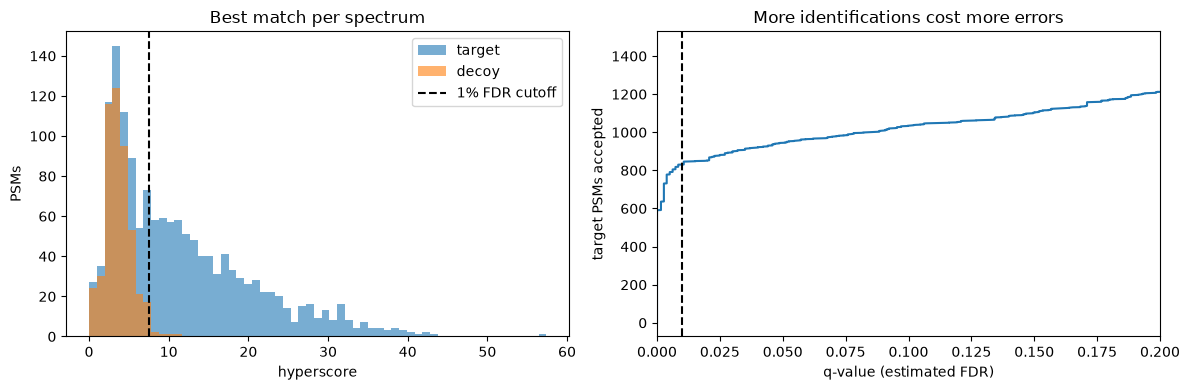

In [ ]:
# Best score first; then walk down the list counting targets and decoys
psms = psms.sort_values("hyperscore", ascending=False).reset_index(drop=True)
psms["n_decoy"] = psms.decoy.astype(int).cumsum()           # decoys at or above this score
psms["n_target"] = (~psms.decoy).astype(int).cumsum()       # targets at or above this score
psms["fdr"] = psms.n_decoy / psms.n_target.clip(lower=1)    # estimated FDR if we cut here
# q-value: the lowest FDR at which each PSM would still pass (take the minimum from the bottom up)
psms["q_value"] = psms.fdr[::-1].cummin()[::-1]

passed = psms[(psms.q_value <= 0.01) & ~psms.decoy]         # accepted: target PSMs at 1% FDR
cut = passed.hyperscore.min()
print(f"PSMs at 1% FDR: {len(passed)} of {len(spectra)} spectra (hyperscore >= {cut:.1f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, psms.hyperscore.max(), 60)
ax[0].hist(psms.hyperscore[~psms.decoy], bins, alpha=0.6, label="target")
ax[0].hist(psms.hyperscore[psms.decoy], bins, alpha=0.6, label="decoy")
ax[0].axvline(cut, color="k", ls="--", label="1% FDR cutoff")
ax[0].set(xlabel="hyperscore", ylabel="PSMs", title="Best match per spectrum"); ax[0].legend()
ax[1].plot(psms.q_value[~psms.decoy], psms.n_target[~psms.decoy])
ax[1].axvline(0.01, color="k", ls="--")
ax[1].set(xlabel="q-value (estimated FDR)", ylabel="target PSMs accepted", xlim=(0, 0.2),
          title="More identifications cost more errors")
plt.tight_layout(); plt.show()

**Question 1.3** In the left plot, the low-scoring targets and the decoys overlap almost perfectly.
What are those low-scoring target matches? And what are the high-scoring targets that have no decoys
next to them?

**Question 1.4** Why do we compare targets with decoys *after* choosing the best match per spectrum,
rather than counting decoy peptides in the whole database?

**Question 1.5** Move the cutoff from 1% to 5% FDR. How many more PSMs do you get, and how many of
those extra PSMs do you expect to be wrong?

---
## 6 · What did we find?

The same spectra were searched with MSGF+, a mature search engine, followed by Percolator, a
machine-learning rescoring step. Let us compare.

In [ ]:
ref = pd.read_csv("hela_2000_reference.csv")
cmp = passed.merge(ref[["usi", "msgf_peptide"]], on="usi", how="left")   # line up the two results

def bare(s):
    '''Sequence without modification labels, with I written as L (they have the same mass).'''
    return re.sub(r"\[[^\]]*\]|-", "", s).replace("I", "L") if isinstance(s, str) else None

both = cmp[cmp.msgf_peptide.notna()]                    # spectra identified by both searches
agree = (both.peptide.str.replace("I", "L") == both.msgf_peptide.map(bare))
print(f"our search:   {len(passed)} PSMs at 1% FDR")
print(f"MSGF+:        {ref.msgf_peptide.notna().sum()} PSMs at 1% FDR on the same spectra")
print(f"both identified {len(both)} spectra, and agree on {agree.sum()} of them ({agree.mean():.1%})")

our search:   830 PSMs at 1% FDR
MSGF+:        1134 PSMs at 1% FDR on the same spectra
both identified 799 spectra, and agree on 784 of them (98.1%)


**Question 1.6** MSGF+ identifies more spectra. Name three things it does that our search does not.
(Hint: look at which modifications the reference peptides carry, and think about what happens when the
instrument picks the second isotope peak of a precursor instead of the first.)

## Seeing a match

A mirror plot puts the measured spectrum (top) against the theoretical b and y ions of the matched
peptide (bottom).

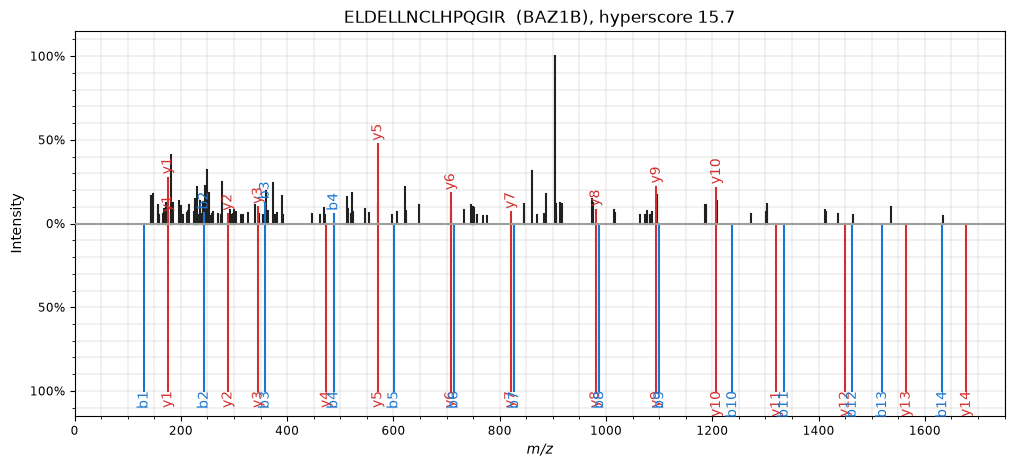

In [ ]:
import spectrum_utils.spectrum as sus
import spectrum_utils.plot as sup

def mirror(usi):
    row = passed[passed.usi == usi].iloc[0]                       # our PSM for this spectrum
    s = next(x for x in spectra if x["params"]["title"] == usi)   # the spectrum itself
    z = int(s["params"]["charge"][0]); pmz = s["params"]["pepmass"][0]
    proforma = row.peptide.replace("C", "C[+57.021464]")          # write the fixed modification out
    obs = sus.MsmsSpectrum(usi, pmz, z, s["m/z array"], s["intensity array"])
    obs = obs.remove_precursor_peak(0.02, "Da").annotate_proforma(proforma, 0.02, "Da", ion_types="by")
    b, y = by_ions(row.peptide)                                   # the theoretical spectrum
    theo = sus.MsmsSpectrum("theoretical", pmz, z, np.sort(np.r_[b, y]), np.ones(len(b) + len(y)))
    theo = theo.annotate_proforma(proforma, 0.02, "Da", ion_types="by")
    fig, ax = plt.subplots(figsize=(12, 5))
    sup.mirror(obs, theo, ax=ax)
    ax.set_title(f"{row.peptide}  ({row.proteins.split(';')[0]}), hyperscore {row.hyperscore:.1f}")
    plt.show()

mirror(passed[passed.charge == 2].usi.iloc[len(passed) // 3])      # a charge-2 match from the middle of the list

## From peptides to proteins

We identified peptides, but biologists ask about proteins. Some peptides are **shared** by several
genes (paralogues, protein families), so a peptide does not always point to one protein. This is the
**protein inference problem**.

In [ ]:
passed = passed.assign(n_genes=passed.proteins.str.count(";") + 1)   # how many genes contain each peptide
print(f"{(passed.n_genes == 1).mean():.0%} of accepted PSMs point to exactly one gene; "
      f"{(passed.n_genes > 1).sum()} PSMs are shared.\n")
print("The most shared peptides:")
print(passed.sort_values("n_genes", ascending=False)[["peptide", "n_genes", "proteins"]]
      .drop_duplicates("peptide").head(5).assign(proteins=lambda d: d.proteins.str[:70]).to_string(index=False))

# Count, per gene, how many different peptides identify it uniquely
unique = passed[passed.n_genes == 1]
per_gene = unique.groupby("proteins").peptide.nunique().sort_values(ascending=False)
print(f"\n{len(per_gene)} genes identified by at least one unique peptide; "
      f"{(per_gene >= 2).sum()} by two or more.")
per_gene.head(10)

91% of accepted PSMs point to exactly one gene; 71 PSMs are shared.

The most shared peptides:
            peptide  n_genes                                                               proteins
        QVHPDTGISSK       19 H2BC26;H2BC12L;H2BC6;H2BC17;H2BC10;H2BC14;H2BC8;H2BC13;H2BC15;H2BC7;H2
            RVTIMPK       18 H3-4;H3-3B;H3C1;H3C2;H3C3;H3C11;H3C12;H3C7;H3C6;H3C10;H3C8;H3-3A;H3C13
            EIQTAVR       18 H2BC12L;H2BC6;H2BC17;H2BC10;H2BC14;H2BC8;H2BC13;H2BC15;H2BC7;H2BC9;H2B
VTIAQGGVLPNIQAVLLPK       17 H2AC25;H2AC4;H2AC16;H2AC17;H2AC6;ENST00000635200.1;H2AC7;H2AC14;H2AC13
         DAVTYTEHAK       14 H4C4;H4C13;H4C6;H4C3;H4C8;H4C11;H4C5;H4C16;H4C9;H4C2;H4C12;H4C1;H4C15;

608 genes identified by at least one unique peptide; 113 by two or more.


proteins
FLNB        6
PLEC        6
AHNAK       5
EPRS1       4
PRPF8       4
KTN1        4
ZNF326      3
PC          3
SNRNP200    3
PRKDC       3
Name: peptide, dtype: int64

**Question 1.7** The most shared peptides often come from histones or actins. Why do these protein
families share so many peptides?

**Question 1.8** Many labs require two unique peptides before they report a protein. What does that
rule protect against, and what does it cost?

---
## What to take away

1. A database search can only find what is in the database. The database is a choice (isoforms,
   variants, contaminants, other organisms) and it limits every result that follows.
2. Precursor mass accuracy narrows millions of peptides to about a hundred candidates per spectrum.
3. A search always returns a best match. Only the **decoys** tell you how many of the matches are
   wrong.
4. **FDR is a property of the whole list**, not of one match: at 1% FDR, about one in a hundred
   accepted PSMs is still wrong, and you do not know which.
5. Peptides are what we measure; proteins are inferred, and shared peptides make that inference
   ambiguous.